In [1]:

# =========================================================
# CELL 1: KHỞI TẠO NOTEBOOK MODEL TRAINING
# =========================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Đường dẫn dự án
PROJECT_DIR = Path(
    r"C:\CreditAI_Project_Starter\CreditAI_Project"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"
METRICS_DIR = REPORTS_DIR / "metrics"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [METRICS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 2. Đọc cấu hình đặc trưng
with open(
    PROCESSED_DIR / "feature_config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

target_col = config["target"]
feature_cols = config["model_features"]

# 3. Đọc Train và Validation
train_df = pd.read_csv(
    PROCESSED_DIR / "train_features.csv",
    index_col="source_index"
)

valid_df = pd.read_csv(
    PROCESSED_DIR / "valid_features.csv",
    index_col="source_index"
)

# 4. Tách X và y
X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_valid = valid_df[feature_cols].copy()
y_valid = valid_df[target_col].copy()

# 5. Kiểm tra dữ liệu
assert X_train.shape == (21000, 28)
assert X_valid.shape == (4500, 28)

assert X_train.columns.equals(X_valid.columns)

assert not X_train.isna().any().any()
assert not X_valid.isna().any().any()

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_valid.to_numpy()).all()

assert set(y_train.unique()).issubset({0, 1})
assert set(y_valid.unique()).issubset({0, 1})

# 6. Hiển thị thông tin
print("===== MODEL TRAINING - DATA CHECK =====")

print("Train:", X_train.shape)
print("Validation:", X_valid.shape)
print("Số đặc trưng:", len(feature_cols))

print("\n===== PHÂN BỐ NHÃN =====")
print("Train default rate:", round(y_train.mean() * 100, 2), "%")
print("Validation default rate:", round(y_valid.mean() * 100, 2), "%")

print("\n===== DANH SÁCH ĐẶC TRƯNG =====")
for i, col in enumerate(feature_cols, start=1):
    print(f"{i:02d}. {col}")

print("\nCELL 1 HOÀN THÀNH!")


===== MODEL TRAINING - DATA CHECK =====
Train: (21000, 28)
Validation: (4500, 28)
Số đặc trưng: 28

===== PHÂN BỐ NHÃN =====
Train default rate: 22.12 %
Validation default rate: 22.11 %

===== DANH SÁCH ĐẶC TRƯNG =====
01. LIMIT_BAL
02. PAY_0
03. PAY_2
04. PAY_3
05. PAY_4
06. PAY_5
07. PAY_6
08. BILL_AMT1
09. BILL_AMT2
10. BILL_AMT3
11. BILL_AMT4
12. BILL_AMT5
13. BILL_AMT6
14. PAY_AMT1
15. PAY_AMT2
16. PAY_AMT3
17. PAY_AMT4
18. PAY_AMT5
19. PAY_AMT6
20. DELAY_COUNT
21. SEVERE_DELAY_COUNT
22. MAX_DELAY
23. ZERO_PAYMENT_COUNT
24. TOTAL_PAYMENT_6M
25. AVG_BILL_6M
26. BILL_CHANGE
27. UTILIZATION_RATIO
28. AVG_UTILIZATION_6M

CELL 1 HOÀN THÀNH!


In [2]:

# =========================================================
# CELL 2: HUẤN LUYỆN LOGISTIC REGRESSION
# =========================================================

import time

# 1. Xây dựng Pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=42
    ))
])

# 2. Huấn luyện mô hình trên Train
print("===== TRAINING LOGISTIC REGRESSION =====")

start_time = time.time()

lr_pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

print("Huấn luyện thành công!")
print(f"Thời gian huấn luyện: {training_time:.2f} giây")

# 3. Dự đoán xác suất trên Validation
lr_valid_proba = lr_pipeline.predict_proba(X_valid)[:, 1]

# 4. Chuyển xác suất thành nhãn với ngưỡng 0.5
lr_valid_pred = (lr_valid_proba >= 0.5).astype(int)

# 5. Tính các chỉ số đánh giá
lr_metrics = {
    "Model": "Logistic Regression",
    "ROC_AUC": roc_auc_score(y_valid, lr_valid_proba),
    "PR_AUC": average_precision_score(
        y_valid, lr_valid_proba
    ),
    "Precision": precision_score(
        y_valid, lr_valid_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_valid, lr_valid_pred, zero_division=0
    ),
    "F1": f1_score(
        y_valid, lr_valid_pred, zero_division=0
    ),
    "Training_Time_Seconds": training_time
}

print("\n===== VALIDATION METRICS =====")
display(
    pd.DataFrame([lr_metrics]).round(4)
)

# 6. Confusion Matrix
print("\n===== CONFUSION MATRIX =====")
cm = confusion_matrix(y_valid, lr_valid_pred)

display(pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

# 7. Báo cáo phân loại chi tiết
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_valid,
    lr_valid_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

# 8. Lưu kết quả đánh giá
lr_metrics_df = pd.DataFrame([lr_metrics])

lr_metrics_df.to_csv(
    METRICS_DIR / "22_logistic_regression_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả Logistic Regression.")
print("CELL 2 HOÀN THÀNH!")


===== TRAINING LOGISTIC REGRESSION =====
Huấn luyện thành công!
Thời gian huấn luyện: 0.25 giây

===== VALIDATION METRICS =====


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1,Training_Time_Seconds
0,Logistic Regression,0.7616,0.5248,0.6807,0.3085,0.4246,0.2454



===== CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,3361,144
Actual 1,688,307



===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

  No Default       0.83      0.96      0.89      3505
     Default       0.68      0.31      0.42       995

    accuracy                           0.82      4500
   macro avg       0.76      0.63      0.66      4500
weighted avg       0.80      0.82      0.79      4500


Đã lưu kết quả Logistic Regression.
CELL 2 HOÀN THÀNH!


===== THRESHOLD ANALYSIS =====


,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,0.10,0.3858,0.2575,0.9437,0.4046,939,2708,56,797
1,0.15,0.6762,0.3750,0.6965,0.4875,693,1155,302,2350
2,0.20,0.7258,0.4196,0.6271,0.5028,624,863,371,2642
3,0.25,0.7618,0.4690,0.5849,0.5206,582,659,413,2846
4,0.30,0.7938,0.5339,0.5307,0.5323,528,461,467,3044
5,0.35,0.8051,0.5738,0.4613,0.5114,459,341,536,3164
6,0.40,0.8122,0.6143,0.4050,0.4882,403,253,592,3252
7,0.45,0.8140,0.6474,0.3487,0.4533,347,189,648,3316
8,0.50,0.8151,0.6807,0.3085,0.4246,307,144,688,3361
9,0.55,0.8107,0.6907,0.2603,0.3781,259,116,736,3389



===== BEST THRESHOLD BY F1 =====
Threshold: 0.30
Precision: 0.5339
Recall: 0.5307
F1: 0.5323
TP: 528
FP: 461
FN: 467


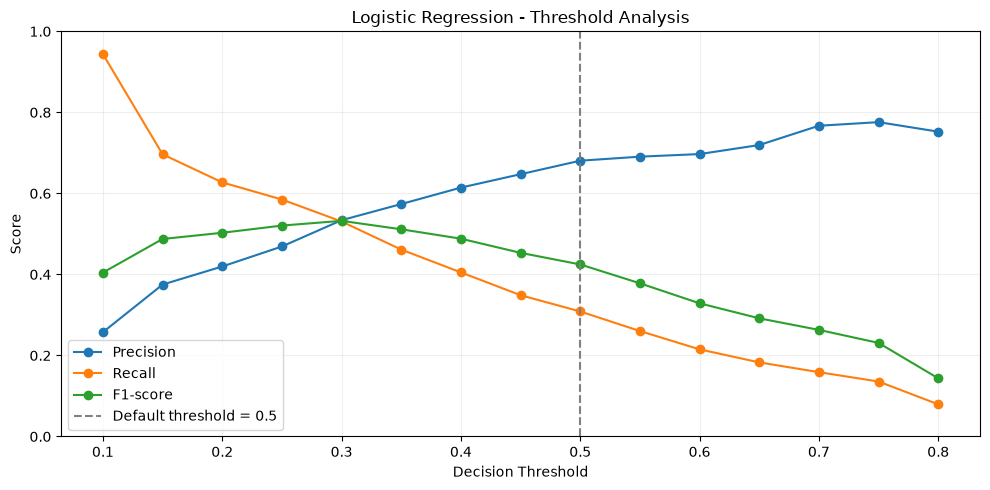


CELL 3 HOÀN THÀNH!


In [3]:

# =========================================================
# CELL 3: PHÂN TÍCH DECISION THRESHOLD
# =========================================================

from sklearn.metrics import accuracy_score

# 1. Các ngưỡng cần thử nghiệm
thresholds = np.arange(0.10, 0.81, 0.05)

threshold_results = []

# 2. Đánh giá từng ngưỡng
for threshold in thresholds:

    y_pred = (
        lr_valid_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

threshold_df = pd.DataFrame(threshold_results)

# 3. Hiển thị bảng
print("===== THRESHOLD ANALYSIS =====")
display(threshold_df.round(4))

# 4. Ngưỡng có F1 cao nhất trong các ngưỡng thử
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("\n===== BEST THRESHOLD BY F1 =====")
print(f"Threshold: {best_row['Threshold']:.2f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1: {best_row['F1']:.4f}")
print(f"TP: {int(best_row['TP'])}")
print(f"FP: {int(best_row['FP'])}")
print(f"FN: {int(best_row['FN'])}")

# 5. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

ax.axvline(
    0.5,
    linestyle="--",
    color="gray",
    label="Default threshold = 0.5"
)

ax.set_title("Logistic Regression - Threshold Analysis")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

figure_path = FIGURES_DIR / "10_lr_threshold_analysis.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Lưu bảng
threshold_df.to_csv(
    METRICS_DIR / "23_lr_threshold_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 3 HOÀN THÀNH!")


In [4]:

# =========================================================
# CELL 4: HUẤN LUYỆN RANDOM FOREST
# =========================================================

from sklearn.ensemble import RandomForestClassifier

# 1. Khởi tạo Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# 2. Huấn luyện trên Train
print("===== TRAINING RANDOM FOREST =====")

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("Huấn luyện thành công!")
print(f"Thời gian huấn luyện: {rf_training_time:.2f} giây")

# 3. Dự đoán xác suất trên Validation
rf_valid_proba = rf_model.predict_proba(X_valid)[:, 1]

# 4. Đánh giá với ngưỡng mặc định 0.5
rf_valid_pred = (
    rf_valid_proba >= 0.5
).astype(int)

# 5. Tính chỉ số đánh giá
rf_metrics = {
    "Model": "Random Forest",
    "ROC_AUC": roc_auc_score(
        y_valid, rf_valid_proba
    ),
    "PR_AUC": average_precision_score(
        y_valid, rf_valid_proba
    ),
    "Precision": precision_score(
        y_valid, rf_valid_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_valid, rf_valid_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_valid, rf_valid_pred,
        zero_division=0
    ),
    "Training_Time_Seconds": rf_training_time
}

print("\n===== RANDOM FOREST VALIDATION METRICS =====")
display(pd.DataFrame([rf_metrics]).round(4))

# 6. Confusion Matrix
print("\n===== CONFUSION MATRIX =====")

rf_cm = confusion_matrix(
    y_valid,
    rf_valid_pred,
    labels=[0, 1]
)

display(pd.DataFrame(
    rf_cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

# 7. Classification Report
print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    y_valid,
    rf_valid_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

# 8. Lưu kết quả
pd.DataFrame([rf_metrics]).to_csv(
    METRICS_DIR / "24_random_forest_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 4 HOÀN THÀNH!")


===== TRAINING RANDOM FOREST =====
Huấn luyện thành công!
Thời gian huấn luyện: 1.91 giây

===== RANDOM FOREST VALIDATION METRICS =====


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1,Training_Time_Seconds
0,Random Forest,0.7753,0.5495,0.6438,0.3487,0.4524,1.9121



===== CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,3313,192
Actual 1,648,347



===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      3505
     Default       0.64      0.35      0.45       995

    accuracy                           0.81      4500
   macro avg       0.74      0.65      0.67      4500
weighted avg       0.79      0.81      0.79      4500


CELL 4 HOÀN THÀNH!


===== RANDOM FOREST THRESHOLD ANALYSIS =====


,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,0.10,0.4887,0.2892,0.9005,0.4378,896,2202,99,1303
1,0.15,0.6336,0.3503,0.7688,0.4813,765,1419,230,2086
2,0.20,0.7198,0.4170,0.6714,0.5144,668,934,327,2571
3,0.25,0.7669,0.4781,0.5930,0.5294,590,644,405,2861
4,0.30,0.7922,0.5293,0.5447,0.5369,542,482,453,3023
5,0.35,0.8053,0.5683,0.4975,0.5305,495,376,500,3129
6,0.40,0.8116,0.6025,0.4342,0.5047,432,285,563,3220
7,0.45,0.8113,0.6170,0.3869,0.4756,385,239,610,3266
8,0.50,0.8133,0.6438,0.3487,0.4524,347,192,648,3313
9,0.55,0.8169,0.6887,0.3136,0.4309,312,141,683,3364



===== BEST RANDOM FOREST THRESHOLD BY F1 =====
Threshold: 0.30
Precision: 0.5293
Recall: 0.5447
F1: 0.5369
TP: 542
FP: 482
FN: 453


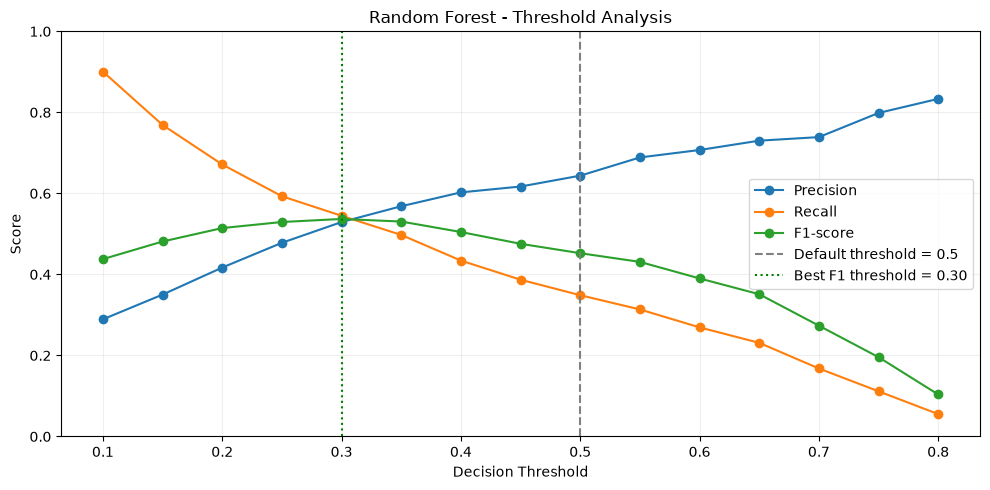


Đã lưu bảng và biểu đồ.
CELL 5 HOÀN THÀNH!


In [5]:

# =========================================================
# CELL 5: RANDOM FOREST - THRESHOLD ANALYSIS
# =========================================================

from sklearn.metrics import accuracy_score

# 1. Các ngưỡng cần thử
thresholds = np.round(
    np.arange(0.10, 0.81, 0.05), 2
)

rf_threshold_results = []

# 2. Đánh giá từng ngưỡng
for threshold in thresholds:

    y_pred = (
        rf_valid_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred, labels=[0, 1]
    ).ravel()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print("===== RANDOM FOREST THRESHOLD ANALYSIS =====")
display(rf_threshold_df.round(4))

# 3. Tìm ngưỡng có F1 cao nhất
rf_best_row = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

rf_best_threshold = float(
    rf_best_row["Threshold"]
)

print("\n===== BEST RANDOM FOREST THRESHOLD BY F1 =====")
print(f"Threshold: {rf_best_threshold:.2f}")
print(f"Precision: {rf_best_row['Precision']:.4f}")
print(f"Recall: {rf_best_row['Recall']:.4f}")
print(f"F1: {rf_best_row['F1']:.4f}")
print(f"TP: {int(rf_best_row['TP'])}")
print(f"FP: {int(rf_best_row['FP'])}")
print(f"FN: {int(rf_best_row['FN'])}")

# 4. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["F1"],
    marker="o",
    label="F1-score"
)

ax.axvline(
    0.5,
    linestyle="--",
    color="gray",
    label="Default threshold = 0.5"
)

ax.axvline(
    rf_best_threshold,
    linestyle=":",
    color="green",
    label=f"Best F1 threshold = {rf_best_threshold:.2f}"
)

ax.set_title("Random Forest - Threshold Analysis")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

figure_path = (
    FIGURES_DIR / "11_rf_threshold_analysis.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Lưu kết quả
rf_threshold_df.to_csv(
    METRICS_DIR / "25_rf_threshold_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu bảng và biểu đồ.")
print("CELL 5 HOÀN THÀNH!")


In [6]:

# =========================================================
# CELL 6: HUẤN LUYỆN HISTOGRAM GRADIENT BOOSTING
# =========================================================

from sklearn.ensemble import HistGradientBoostingClassifier

# 1. Khởi tạo mô hình
hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

# 2. Huấn luyện trên Train
print("===== TRAINING HIST GRADIENT BOOSTING =====")

start_time = time.time()

hgb_model.fit(X_train, y_train)

hgb_training_time = time.time() - start_time

print("Huấn luyện thành công!")
print(f"Thời gian huấn luyện: {hgb_training_time:.2f} giây")

# 3. Dự đoán xác suất trên Validation
hgb_valid_proba = hgb_model.predict_proba(X_valid)[:, 1]

# 4. Dự đoán nhãn với ngưỡng mặc định 0.5
hgb_valid_pred = (
    hgb_valid_proba >= 0.5
).astype(int)

# 5. Đánh giá
hgb_metrics = {
    "Model": "Hist Gradient Boosting",
    "ROC_AUC": roc_auc_score(
        y_valid, hgb_valid_proba
    ),
    "PR_AUC": average_precision_score(
        y_valid, hgb_valid_proba
    ),
    "Precision": precision_score(
        y_valid, hgb_valid_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_valid, hgb_valid_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_valid, hgb_valid_pred,
        zero_division=0
    ),
    "Training_Time_Seconds": hgb_training_time
}

print("\n===== HGB VALIDATION METRICS =====")
display(pd.DataFrame([hgb_metrics]).round(4))

# 6. Confusion Matrix
print("\n===== CONFUSION MATRIX =====")

hgb_cm = confusion_matrix(
    y_valid,
    hgb_valid_pred,
    labels=[0, 1]
)

display(pd.DataFrame(
    hgb_cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

# 7. Classification Report
print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    y_valid,
    hgb_valid_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

# 8. Lưu kết quả
pd.DataFrame([hgb_metrics]).to_csv(
    METRICS_DIR / "26_hgb_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 6 HOÀN THÀNH!")


===== TRAINING HIST GRADIENT BOOSTING =====
Huấn luyện thành công!
Thời gian huấn luyện: 3.13 giây

===== HGB VALIDATION METRICS =====


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1,Training_Time_Seconds
0,Hist Gradient Boosting,0.7781,0.5468,0.6496,0.3578,0.4614,3.1316



===== CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,3313,192
Actual 1,639,356



===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      3505
     Default       0.65      0.36      0.46       995

    accuracy                           0.82      4500
   macro avg       0.74      0.65      0.67      4500
weighted avg       0.80      0.82      0.79      4500


CELL 6 HOÀN THÀNH!


===== HGB THRESHOLD ANALYSIS =====


,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,0.10,0.5080,0.2980,0.9035,0.4482,899,2118,96,1387
1,0.15,0.6418,0.3554,0.7618,0.4847,758,1375,237,2130
2,0.20,0.7271,0.4255,0.6683,0.5199,665,898,330,2607
3,0.25,0.7693,0.4826,0.6000,0.5349,597,640,398,2865
4,0.30,0.7869,0.5172,0.5427,0.5297,540,504,455,3001
5,0.35,0.8044,0.5685,0.4794,0.5202,477,362,518,3143
6,0.40,0.8089,0.5980,0.4141,0.4893,412,277,583,3228
7,0.45,0.8116,0.6219,0.3769,0.4693,375,228,620,3277
8,0.50,0.8153,0.6496,0.3578,0.4614,356,192,639,3313
9,0.55,0.8169,0.6770,0.3286,0.4425,327,156,668,3349



===== BEST HGB THRESHOLD BY F1 =====
Threshold: 0.25
Precision: 0.4826
Recall: 0.6000
F1: 0.5349
TP: 597
FP: 640
FN: 398


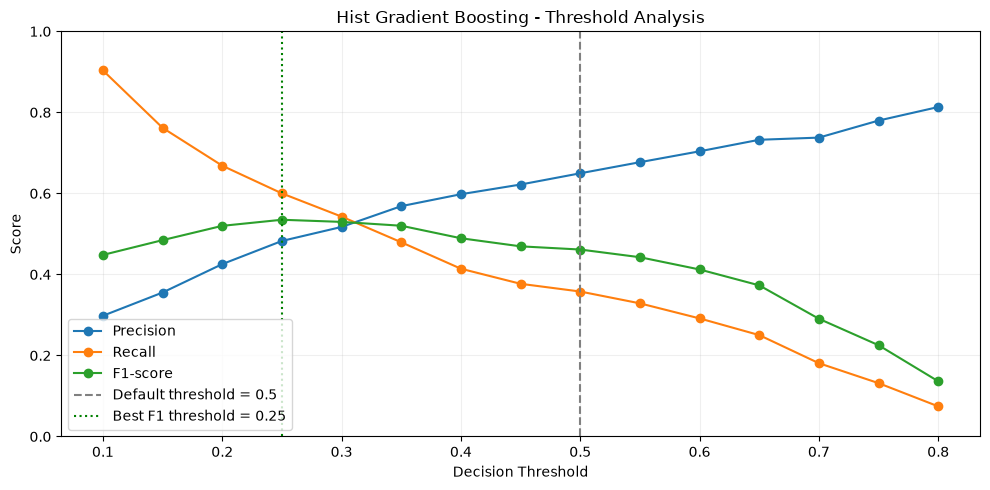


Đã lưu bảng và biểu đồ.
CELL 7 HOÀN THÀNH!


In [7]:

# =========================================================
# CELL 7: HIST GRADIENT BOOSTING - THRESHOLD ANALYSIS
# =========================================================

from sklearn.metrics import accuracy_score

# 1. Danh sách ngưỡng thử nghiệm
thresholds = np.round(
    np.arange(0.10, 0.81, 0.05), 2
)

hgb_threshold_results = []

# 2. Đánh giá từng ngưỡng
for threshold in thresholds:

    y_pred = (
        hgb_valid_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred, labels=[0, 1]
    ).ravel()

    hgb_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

hgb_threshold_df = pd.DataFrame(
    hgb_threshold_results
)

print("===== HGB THRESHOLD ANALYSIS =====")
display(hgb_threshold_df.round(4))

# 3. Tìm ngưỡng đạt F1 cao nhất
hgb_best_row = hgb_threshold_df.loc[
    hgb_threshold_df["F1"].idxmax()
]

hgb_best_threshold = float(
    hgb_best_row["Threshold"]
)

print("\n===== BEST HGB THRESHOLD BY F1 =====")
print(f"Threshold: {hgb_best_threshold:.2f}")
print(f"Precision: {hgb_best_row['Precision']:.4f}")
print(f"Recall: {hgb_best_row['Recall']:.4f}")
print(f"F1: {hgb_best_row['F1']:.4f}")
print(f"TP: {int(hgb_best_row['TP'])}")
print(f"FP: {int(hgb_best_row['FP'])}")
print(f"FN: {int(hgb_best_row['FN'])}")

# 4. Vẽ biểu đồ Precision, Recall, F1
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    hgb_threshold_df["Threshold"],
    hgb_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    hgb_threshold_df["Threshold"],
    hgb_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    hgb_threshold_df["Threshold"],
    hgb_threshold_df["F1"],
    marker="o",
    label="F1-score"
)

ax.axvline(
    0.5,
    linestyle="--",
    color="gray",
    label="Default threshold = 0.5"
)

ax.axvline(
    hgb_best_threshold,
    linestyle=":",
    color="green",
    label=f"Best F1 threshold = {hgb_best_threshold:.2f}"
)

ax.set_title("Hist Gradient Boosting - Threshold Analysis")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

figure_path = (
    FIGURES_DIR / "12_hgb_threshold_analysis.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Lưu bảng kết quả
hgb_threshold_df.to_csv(
    METRICS_DIR / "27_hgb_threshold_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu bảng và biểu đồ.")
print("CELL 7 HOÀN THÀNH!")


In [8]:

# =========================================================
# CELL 8: ABLATION STUDY - 19 VS 28 FEATURES
# =========================================================

from sklearn.base import clone

# 1. Lấy danh sách đặc trưng gốc
base_features = config["base_features"]
full_features = config["model_features"]

assert len(base_features) == 19
assert len(full_features) == 28

# 2. Danh sách mô hình đã huấn luyện
model_templates = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_model,
    "Hist Gradient Boosting": hgb_model
}

# 3. So sánh hai bộ đặc trưng
feature_sets = {
    "Original 19": base_features,
    "Engineered 28": full_features
}

ablation_results = []

for model_name, model_template in model_templates.items():

    for feature_set_name, features in feature_sets.items():

        print(
            f"Training: {model_name} - {feature_set_name}"
        )

        # Tạo mô hình mới với cùng tham số
        model = clone(model_template)

        # Huấn luyện chỉ trên Train
        model.fit(
            X_train[features],
            y_train
        )

        # Dự đoán trên Validation
        proba = model.predict_proba(
            X_valid[features]
        )[:, 1]

        # Đánh giá khả năng phân biệt
        roc_auc = roc_auc_score(
            y_valid, proba
        )

        pr_auc = average_precision_score(
            y_valid, proba
        )

        # Tìm F1 tốt nhất trong các ngưỡng đã thử
        thresholds = np.round(
            np.arange(0.10, 0.81, 0.05), 2
        )

        f1_scores = [
            f1_score(
                y_valid,
                (proba >= t).astype(int),
                zero_division=0
            )
            for t in thresholds
        ]

        best_idx = int(np.argmax(f1_scores))

        ablation_results.append({
            "Model": model_name,
            "Feature_Set": feature_set_name,
            "N_Features": len(features),
            "ROC_AUC": roc_auc,
            "PR_AUC": pr_auc,
            "Best_Threshold": thresholds[best_idx],
            "Best_F1": f1_scores[best_idx]
        })

# 4. Bảng kết quả
ablation_df = pd.DataFrame(ablation_results)

print("\n===== FEATURE ENGINEERING ABLATION =====")
display(ablation_df.round(4))

# 5. Tính chênh lệch giữa 28 và 19 đặc trưng
comparison = ablation_df.pivot(
    index="Model",
    columns="Feature_Set",
    values=["ROC_AUC", "PR_AUC", "Best_F1"]
)

delta_df = pd.DataFrame(index=comparison.index)

for metric in ["ROC_AUC", "PR_AUC", "Best_F1"]:
    delta_df[f"Delta_{metric}"] = (
        comparison[(metric, "Engineered 28")]
        - comparison[(metric, "Original 19")]
    )

print("\n===== MỨC CẢI THIỆN KHI THÊM ĐẶC TRƯNG =====")
display(delta_df.round(4))

# 6. Lưu kết quả
ablation_df.to_csv(
    METRICS_DIR / "28_feature_ablation.csv",
    index=False,
    encoding="utf-8-sig"
)

delta_df.to_csv(
    METRICS_DIR / "29_feature_ablation_delta.csv",
    encoding="utf-8-sig"
)

print("\nCELL 8 HOÀN THÀNH!")


Training: Logistic Regression - Original 19
Training: Logistic Regression - Engineered 28
Training: Random Forest - Original 19
Training: Random Forest - Engineered 28
Training: Hist Gradient Boosting - Original 19
Training: Hist Gradient Boosting - Engineered 28

===== FEATURE ENGINEERING ABLATION =====


,Model,Feature_Set,N_Features,ROC_AUC,PR_AUC,Best_Threshold,Best_F1
0,Logistic Regression,Original 19,19,0.7142,0.5030,0.25,0.5086
1,Logistic Regression,Engineered 28,28,0.7616,0.5248,0.30,0.5323
2,Random Forest,Original 19,19,0.7716,0.5394,0.30,0.5353
3,Random Forest,Engineered 28,28,0.7753,0.5495,0.30,0.5369
4,Hist Gradient Boosting,Original 19,19,0.7720,0.5410,0.25,0.5333
5,Hist Gradient Boosting,Engineered 28,28,0.7781,0.5468,0.25,0.5349



===== MỨC CẢI THIỆN KHI THÊM ĐẶC TRƯNG =====


,Delta_ROC_AUC,Delta_PR_AUC,Delta_Best_F1
Model,,,
Hist Gradient Boosting,0.0061,0.0058,0.0016
Logistic Regression,0.0475,0.0217,0.0236
Random Forest,0.0037,0.0100,0.0016



CELL 8 HOÀN THÀNH!


In [9]:

# =========================================================
# CELL 9: RANDOM FOREST HYPERPARAMETER TUNING
# =========================================================

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import RandomForestClassifier
import time

# 1. Khởi tạo mô hình
rf_tuning_model = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# 2. Không gian siêu tham số
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [8, 12, 16, None],
    "min_samples_leaf": [2, 5, 10],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", 0.7]
}

# 3. Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. Randomized Search
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("===== RANDOM FOREST HYPERPARAMETER TUNING =====")

start_time = time.time()

# Chỉ sử dụng Train để tìm tham số
rf_search.fit(X_train, y_train)

tuning_time = time.time() - start_time

print("\n===== KẾT QUẢ TỐI ƯU =====")
print("Best CV PR-AUC:", round(rf_search.best_score_, 4))
print("Best Parameters:", rf_search.best_params_)
print("Tuning Time:", round(tuning_time, 2), "giây")

# 5. Đánh giá trên Validation
rf_tuned_model = rf_search.best_estimator_

rf_tuned_proba = rf_tuned_model.predict_proba(
    X_valid
)[:, 1]

rf_tuned_roc = roc_auc_score(
    y_valid, rf_tuned_proba
)

rf_tuned_pr = average_precision_score(
    y_valid, rf_tuned_proba
)

print("\n===== SO SÁNH BASELINE VS TUNED =====")

rf_tuning_comparison = pd.DataFrame([
    {
        "Model": "Random Forest Baseline",
        "ROC_AUC": rf_metrics["ROC_AUC"],
        "PR_AUC": rf_metrics["PR_AUC"]
    },
    {
        "Model": "Random Forest Tuned",
        "ROC_AUC": rf_tuned_roc,
        "PR_AUC": rf_tuned_pr
    }
])

display(rf_tuning_comparison.round(4))

# 6. Lưu kết quả
rf_tuning_comparison.to_csv(
    METRICS_DIR / "30_rf_tuning_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 9 HOÀN THÀNH!")


===== RANDOM FOREST HYPERPARAMETER TUNING =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== KẾT QUẢ TỐI ƯU =====
Best CV PR-AUC: 0.5622
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 8}
Tuning Time: 185.84 giây

===== SO SÁNH BASELINE VS TUNED =====


,Model,ROC_AUC,PR_AUC
0,Random Forest Baseline,0.7753,0.5495
1,Random Forest Tuned,0.7781,0.5538



CELL 9 HOÀN THÀNH!


===== RF TUNED THRESHOLD ANALYSIS =====


,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,0.10,0.4864,0.2899,0.9126,0.4400,908,2224,87,1281
1,0.15,0.6511,0.3613,0.7528,0.4883,749,1324,246,2181
2,0.20,0.7331,0.4317,0.6543,0.5202,651,857,344,2648
3,0.25,0.7778,0.4978,0.5749,0.5336,572,577,423,2928
4,0.30,0.7996,0.5481,0.5327,0.5403,530,437,465,3068
5,0.35,0.8087,0.5848,0.4643,0.5176,462,328,533,3177
6,0.40,0.8107,0.6050,0.4141,0.4916,412,269,583,3236
7,0.45,0.8140,0.6353,0.3729,0.4699,371,213,624,3292
8,0.50,0.8180,0.6686,0.3508,0.4601,349,173,646,3332
9,0.55,0.8162,0.6803,0.3186,0.4339,317,149,678,3356



===== BEST RF TUNED THRESHOLD =====
Threshold: 0.30
Precision: 0.5481
Recall: 0.5327
F1: 0.5403
TP: 530
FP: 437
FN: 465

===== RF BASELINE VS RF TUNED =====


,Model,ROC_AUC,PR_AUC,Threshold,Precision,Recall,F1
0,RF Baseline,0.7753,0.5495,0.3,0.5293,0.5447,0.5369
1,RF Tuned,0.7781,0.5538,0.3,0.5481,0.5327,0.5403


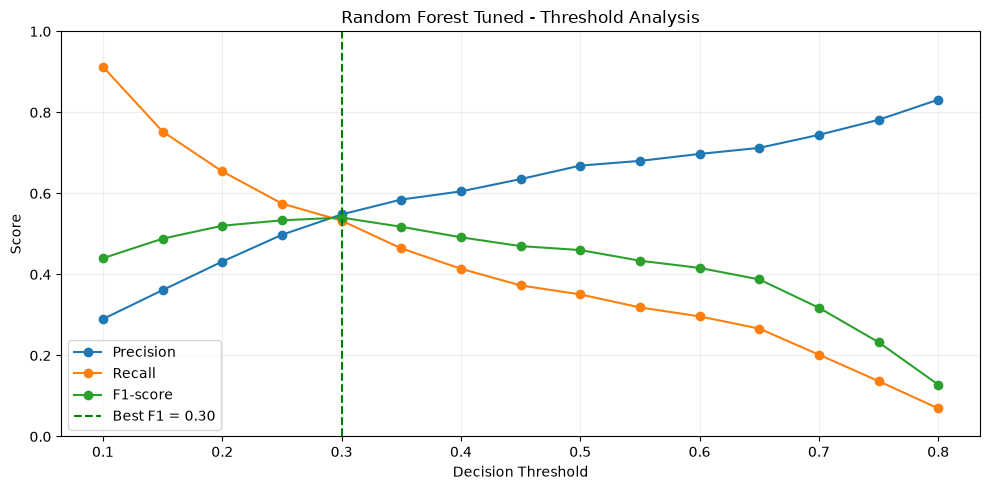


CELL 10 HOÀN THÀNH!


In [10]:

# =========================================================
# CELL 10: RANDOM FOREST TUNED - THRESHOLD ANALYSIS
# =========================================================

from sklearn.metrics import accuracy_score

# 1. Các ngưỡng thử nghiệm
thresholds = np.round(
    np.arange(0.10, 0.81, 0.05), 2
)

rf_tuned_threshold_results = []

# 2. Đánh giá từng ngưỡng trên Validation
for threshold in thresholds:

    y_pred = (
        rf_tuned_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred, labels=[0, 1]
    ).ravel()

    rf_tuned_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

rf_tuned_threshold_df = pd.DataFrame(
    rf_tuned_threshold_results
)

print("===== RF TUNED THRESHOLD ANALYSIS =====")
display(rf_tuned_threshold_df.round(4))

# 3. Tìm ngưỡng F1 cao nhất
rf_tuned_best_row = rf_tuned_threshold_df.loc[
    rf_tuned_threshold_df["F1"].idxmax()
]

rf_tuned_best_threshold = float(
    rf_tuned_best_row["Threshold"]
)

print("\n===== BEST RF TUNED THRESHOLD =====")
print(f"Threshold: {rf_tuned_best_threshold:.2f}")
print(f"Precision: {rf_tuned_best_row['Precision']:.4f}")
print(f"Recall: {rf_tuned_best_row['Recall']:.4f}")
print(f"F1: {rf_tuned_best_row['F1']:.4f}")
print(f"TP: {int(rf_tuned_best_row['TP'])}")
print(f"FP: {int(rf_tuned_best_row['FP'])}")
print(f"FN: {int(rf_tuned_best_row['FN'])}")

# 4. So sánh RF Baseline và RF Tuned
rf_baseline_best = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

rf_compare = pd.DataFrame([
    {
        "Model": "RF Baseline",
        "ROC_AUC": rf_metrics["ROC_AUC"],
        "PR_AUC": rf_metrics["PR_AUC"],
        "Threshold": rf_baseline_best["Threshold"],
        "Precision": rf_baseline_best["Precision"],
        "Recall": rf_baseline_best["Recall"],
        "F1": rf_baseline_best["F1"]
    },
    {
        "Model": "RF Tuned",
        "ROC_AUC": rf_tuned_roc,
        "PR_AUC": rf_tuned_pr,
        "Threshold": rf_tuned_best_row["Threshold"],
        "Precision": rf_tuned_best_row["Precision"],
        "Recall": rf_tuned_best_row["Recall"],
        "F1": rf_tuned_best_row["F1"]
    }
])

print("\n===== RF BASELINE VS RF TUNED =====")
display(rf_compare.round(4))

# 5. Biểu đồ
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    rf_tuned_threshold_df["Threshold"],
    rf_tuned_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    rf_tuned_threshold_df["Threshold"],
    rf_tuned_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    rf_tuned_threshold_df["Threshold"],
    rf_tuned_threshold_df["F1"],
    marker="o",
    label="F1-score"
)

ax.axvline(
    rf_tuned_best_threshold,
    linestyle="--",
    color="green",
    label=f"Best F1 = {rf_tuned_best_threshold:.2f}"
)

ax.set_title("Random Forest Tuned - Threshold Analysis")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "13_rf_tuned_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Lưu kết quả
rf_tuned_threshold_df.to_csv(
    METRICS_DIR / "31_rf_tuned_threshold.csv",
    index=False,
    encoding="utf-8-sig"
)

rf_compare.to_csv(
    METRICS_DIR / "32_rf_baseline_vs_tuned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 10 HOÀN THÀNH!")


In [11]:

# =========================================================
# CELL 11: HIST GRADIENT BOOSTING HYPERPARAMETER TUNING
# =========================================================

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import time

# 1. Khởi tạo mô hình
hgb_tuning_model = HistGradientBoostingClassifier(
    early_stopping=False,
    random_state=42
)

# 2. Không gian siêu tham số
hgb_param_distributions = {
    "max_iter": [100, 150, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_leaf_nodes": [15, 31, 63],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [10, 20, 40],
    "l2_regularization": [0.0, 1.0, 5.0]
}

# 3. Cross-Validation
hgb_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. Randomized Search
hgb_search = RandomizedSearchCV(
    estimator=hgb_tuning_model,
    param_distributions=hgb_param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=hgb_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("===== HIST GRADIENT BOOSTING TUNING =====")

start_time = time.time()

# Chỉ dùng Train để tìm tham số
hgb_search.fit(X_train, y_train)

hgb_tuning_time = time.time() - start_time

print("\n===== KẾT QUẢ TỐI ƯU =====")
print("Best CV PR-AUC:", round(hgb_search.best_score_, 4))
print("Best Parameters:", hgb_search.best_params_)
print("Tuning Time:", round(hgb_tuning_time, 2), "giây")

# 5. Lấy mô hình tốt nhất
hgb_tuned_model = hgb_search.best_estimator_

# 6. Dự đoán xác suất trên Validation
hgb_tuned_proba = hgb_tuned_model.predict_proba(
    X_valid
)[:, 1]

# 7. Tính các chỉ số
hgb_tuned_roc = roc_auc_score(
    y_valid, hgb_tuned_proba
)

hgb_tuned_pr = average_precision_score(
    y_valid, hgb_tuned_proba
)

# 8. So sánh Baseline và Tuned
hgb_tuning_comparison = pd.DataFrame([
    {
        "Model": "HGB Baseline",
        "ROC_AUC": hgb_metrics["ROC_AUC"],
        "PR_AUC": hgb_metrics["PR_AUC"]
    },
    {
        "Model": "HGB Tuned",
        "ROC_AUC": hgb_tuned_roc,
        "PR_AUC": hgb_tuned_pr
    }
])

print("\n===== HGB BASELINE VS TUNED =====")
display(hgb_tuning_comparison.round(4))

# 9. Lưu kết quả
hgb_tuning_comparison.to_csv(
    METRICS_DIR / "33_hgb_tuning_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(
    hgb_search.cv_results_
).to_csv(
    METRICS_DIR / "34_hgb_cv_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 11 HOÀN THÀNH!")


===== HIST GRADIENT BOOSTING TUNING =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== KẾT QUẢ TỐI ƯU =====
Best CV PR-AUC: 0.5658
Best Parameters: {'min_samples_leaf': 40, 'max_leaf_nodes': 63, 'max_iter': 200, 'max_depth': 3, 'learning_rate': 0.03, 'l2_regularization': 5.0}
Tuning Time: 20.01 giây

===== HGB BASELINE VS TUNED =====


,Model,ROC_AUC,PR_AUC
0,HGB Baseline,0.7781,0.5468
1,HGB Tuned,0.7812,0.5556



CELL 11 HOÀN THÀNH!


===== HGB TUNED THRESHOLD ANALYSIS =====


,Threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,0.10,0.4769,0.2869,0.9196,0.4374,915,2274,80,1231
1,0.15,0.6398,0.3559,0.7769,0.4882,773,1399,222,2106
2,0.20,0.7289,0.4277,0.6693,0.5219,666,891,329,2614
3,0.25,0.7727,0.4884,0.5940,0.5361,591,619,404,2886
4,0.30,0.7960,0.5400,0.5226,0.5312,520,443,475,3062
5,0.35,0.8122,0.5964,0.4663,0.5234,464,314,531,3191
6,0.40,0.8142,0.6210,0.4101,0.4939,408,249,587,3256
7,0.45,0.8144,0.6361,0.3759,0.4725,374,214,621,3291
8,0.50,0.8173,0.6617,0.3558,0.4627,354,181,641,3324
9,0.55,0.8169,0.6792,0.3256,0.4402,324,153,671,3352



===== BEST HGB TUNED THRESHOLD =====
Threshold: 0.25
Precision: 0.4884
Recall: 0.5940
F1: 0.5361
TP: 591
FP: 619
FN: 404

===== HGB BASELINE VS TUNED =====


,Model,ROC_AUC,PR_AUC,Threshold,Precision,Recall,F1
0,HGB Baseline,0.7781,0.5468,0.25,0.4826,0.600,0.5349
1,HGB Tuned,0.7812,0.5556,0.25,0.4884,0.594,0.5361


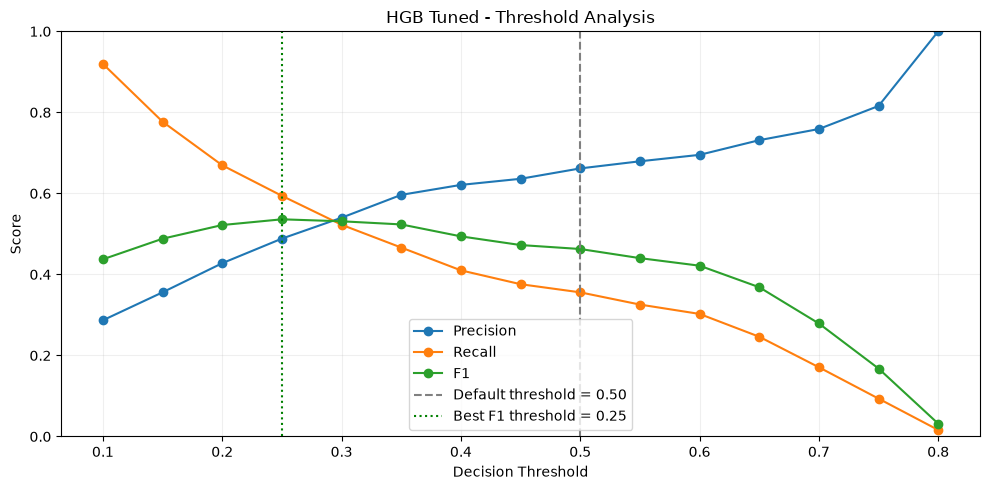


CELL 12 HOÀN THÀNH!


In [12]:

# =========================================================
# CELL 12: HGB TUNED - THRESHOLD ANALYSIS
# =========================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# 1. Danh sách ngưỡng
thresholds = np.round(np.arange(0.10, 0.81, 0.05), 2)

hgb_tuned_threshold_results = []

# 2. Đánh giá trên Validation
for threshold in thresholds:

    y_pred = (hgb_tuned_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, y_pred, labels=[0, 1]
    ).ravel()

    hgb_tuned_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

hgb_tuned_threshold_df = pd.DataFrame(
    hgb_tuned_threshold_results
)

print("===== HGB TUNED THRESHOLD ANALYSIS =====")
display(hgb_tuned_threshold_df.round(4))

# 3. Tìm ngưỡng F1 tốt nhất
hgb_tuned_best_row = hgb_tuned_threshold_df.loc[
    hgb_tuned_threshold_df["F1"].idxmax()
]

hgb_tuned_best_threshold = float(
    hgb_tuned_best_row["Threshold"]
)

print("\n===== BEST HGB TUNED THRESHOLD =====")
print(f"Threshold: {hgb_tuned_best_threshold:.2f}")
print(f"Precision: {hgb_tuned_best_row['Precision']:.4f}")
print(f"Recall: {hgb_tuned_best_row['Recall']:.4f}")
print(f"F1: {hgb_tuned_best_row['F1']:.4f}")
print(f"TP: {int(hgb_tuned_best_row['TP'])}")
print(f"FP: {int(hgb_tuned_best_row['FP'])}")
print(f"FN: {int(hgb_tuned_best_row['FN'])}")

# 4. So sánh HGB Baseline và HGB Tuned
hgb_baseline_best = hgb_threshold_df.loc[
    hgb_threshold_df["F1"].idxmax()
]

hgb_compare = pd.DataFrame([
    {
        "Model": "HGB Baseline",
        "ROC_AUC": hgb_metrics["ROC_AUC"],
        "PR_AUC": hgb_metrics["PR_AUC"],
        "Threshold": hgb_baseline_best["Threshold"],
        "Precision": hgb_baseline_best["Precision"],
        "Recall": hgb_baseline_best["Recall"],
        "F1": hgb_baseline_best["F1"]
    },
    {
        "Model": "HGB Tuned",
        "ROC_AUC": hgb_tuned_roc,
        "PR_AUC": hgb_tuned_pr,
        "Threshold": hgb_tuned_best_row["Threshold"],
        "Precision": hgb_tuned_best_row["Precision"],
        "Recall": hgb_tuned_best_row["Recall"],
        "F1": hgb_tuned_best_row["F1"]
    }
])

print("\n===== HGB BASELINE VS TUNED =====")
display(hgb_compare.round(4))

# 5. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(10, 5))

for metric in ["Precision", "Recall", "F1"]:
    ax.plot(
        hgb_tuned_threshold_df["Threshold"],
        hgb_tuned_threshold_df[metric],
        marker="o",
        label=metric
    )

ax.axvline(
    0.50,
    color="gray",
    linestyle="--",
    label="Default threshold = 0.50"
)

ax.axvline(
    hgb_tuned_best_threshold,
    color="green",
    linestyle=":",
    label=f"Best F1 threshold = {hgb_tuned_best_threshold:.2f}"
)

ax.set_title("HGB Tuned - Threshold Analysis")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "14_hgb_tuned_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Lưu kết quả
hgb_tuned_threshold_df.to_csv(
    METRICS_DIR / "35_hgb_tuned_threshold.csv",
    index=False,
    encoding="utf-8-sig"
)

hgb_compare.to_csv(
    METRICS_DIR / "36_hgb_baseline_vs_tuned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 12 HOÀN THÀNH!")


In [13]:

# =========================================================
# CELL 13: FINAL MODEL SELECTION AND EXPORT
# =========================================================

import json
import joblib
from pathlib import Path
from datetime import datetime, timezone

# 1. Tạo thư mục lưu mô hình
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Chọn mô hình dựa trên PR-AUC Validation
selected_model = hgb_tuned_model
selected_model_name = "Hist Gradient Boosting Tuned"
selected_threshold = float(hgb_tuned_best_threshold)

# 3. Giữ đúng thứ tự 28 đặc trưng
selected_features = X_train.columns.tolist()

assert len(selected_features) == 28
assert X_valid.columns.tolist() == selected_features

# 4. Lưu mô hình đã huấn luyện
model_path = MODELS_DIR / "credit_default_hgb.joblib"

joblib.dump(selected_model, model_path)

# 5. Lưu cấu hình mô hình
model_config = {
    "model_name": selected_model_name,
    "model_file": model_path.name,
    "feature_columns": selected_features,
    "n_features": len(selected_features),
    "decision_threshold": selected_threshold,
    "threshold_selection": "Best F1 on Validation grid",
    "model_selection": "Highest Validation Average Precision",
    "validation_roc_auc": float(hgb_tuned_roc),
    "validation_average_precision": float(hgb_tuned_pr),
    "validation_f1": float(hgb_tuned_best_row["F1"]),
    "hyperparameters": hgb_search.best_params_,
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

config_path = MODELS_DIR / "credit_default_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        model_config,
        f,
        indent=4,
        ensure_ascii=False
    )

# 6. Kiểm tra file đã lưu
loaded_model = joblib.load(model_path)

original_proba = selected_model.predict_proba(
    X_valid[selected_features]
)[:, 1]

loaded_proba = loaded_model.predict_proba(
    X_valid[selected_features]
)[:, 1]

assert np.allclose(original_proba, loaded_proba)

print("===== FINAL MODEL SELECTION =====")
print("Selected Model:", selected_model_name)
print("Number of Features:", len(selected_features))
print("Decision Threshold:", selected_threshold)
print("Validation ROC-AUC:", round(hgb_tuned_roc, 4))
print("Validation PR-AUC:", round(hgb_tuned_pr, 4))
print("Validation F1:", round(hgb_tuned_best_row["F1"], 4))

print("\n===== SAVED FILES =====")
print("Model:", model_path)
print("Config:", config_path)
print("Reload Verification: PASSED")

print("\nCELL 13 HOÀN THÀNH!")


===== FINAL MODEL SELECTION =====
Selected Model: Hist Gradient Boosting Tuned
Number of Features: 28
Decision Threshold: 0.25
Validation ROC-AUC: 0.7812
Validation PR-AUC: 0.5556
Validation F1: 0.5361

===== SAVED FILES =====
Model: C:\CreditAI_Project_Starter\CreditAI_Project\models\credit_default_hgb.joblib
Config: C:\CreditAI_Project_Starter\CreditAI_Project\models\credit_default_config.json
Reload Verification: PASSED

CELL 13 HOÀN THÀNH!
